# Machine learning

Nesta etapa, será desenvolvido modelos de Machine Learning utilizando os dados do arquivo sinistros_sp_2025_limpo_eda. O objetivo é treinar modelos de classificação capaz de identificar os acidentes de trânsito como fatais ou não fatais, buscando analisar os fatores associados à gravidade dos sinistros no município de São Paulo em 2025.

Ao longo do notebook, serão realizadas etapas de preparação dos dados, seleção das métricas e da variável-alvo, divisão dos dados em conjuntos de treino e teste, tratamento do desbalanceamento das classes, treinamento dos modelos e avaliação de seus resultados. Por fim, serão analisadas as métricas de desempenho para verificar a capacidade do modelo de classificar corretamente os sinistros.

## Importação das bibliotecas

In [6]:
# Manipulação de Dados
import pandas as pd
import numpy as np

# Visualização Gráfica
import matplotlib.pyplot as plt

#Separação dos dados: treino e teste
from sklearn.model_selection import cross_validate, StratifiedKFold, train_test_split 


# Codificação de variáveis categóricas
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

# Criação
from sklearn.compose import make_column_selector, ColumnTransformer
from sklearn.pipeline import Pipeline as SklearnPipeline

# Modelos de Aprendizado de Máquina
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from lightgbm import LGBMClassifier

# Métricas de avaliação dos modelos
from sklearn.metrics import (  #Métricas de Avaliação
    
    ConfusionMatrixDisplay,
    confusion_matrix,
    classification_report,
    PrecisionRecallDisplay,
    precision_recall_curve,
    average_precision_score,
    RocCurveDisplay,
    roc_auc_score,
    roc_curve,
    auc
) 

## Carregamento dos dados

In [7]:
# Carregar a base
df_original = pd.read_csv(
    "../data/processed/sinistros_sp_2025_limpo_eda.csv",
    sep=";",
    encoding="utf-8-sig",
    low_memory=False
)
# Criar uma copia da base de dados
df = df_original.copy()

# mostrar os 5 primeiros registros
df.head()

,id_sinistro,tipo_registro,data_sinistro,ano_sinistro,mes_sinistro,dia_sinistro,hora_sinistro,ano_mes_sinistro,dia_da_semana,turno,...,tp_sinistro_choque,tp_sinistro_atrop_animal,tp_sinistro_capotamento,tp_sinistro_engavetamento,tp_sinistro_tombamento,tp_sinistro_outros,tp_sinistro_nao_disponivel,hora,latitude_num,longitude_num
0,2523341,NOTIFICACAO,01/01/2025,2025,1,1,03:11,2025/01,Quarta-feira,MADRUGADA,...,NaN,NaN,NaN,NaN,NaN,NaN,S,NaN,NaN,NaN
1,2467785,SINISTRO FATAL,01/01/2025,2025,1,1,02:40,2025/01,Quarta-feira,MADRUGADA,...,S,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-23.775437,-46.681749
2,2517646,NOTIFICACAO,01/01/2025,2025,1,1,01:15,2025/01,Quarta-feira,MADRUGADA,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2524480,SINISTRO NAO FATAL,01/01/2025,2025,1,1,03:08,2025/01,Quarta-feira,MADRUGADA,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-23.507866,-46.491797
4,2531534,SINISTRO NAO FATAL,02/01/2025,2025,1,2,20:40,2025/01,Quinta-feira,NOITE,...,NaN,NaN,NaN,NaN,NaN,S,NaN,NaN,-23.575500,-46.712900


In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 42671 entries, 0 to 42670
Data columns (total 53 columns):
 #   Column                              Non-Null Count  Dtype  
---  ------                              --------------  -----  
 0   id_sinistro                         42671 non-null  int64  
 1   tipo_registro                       42671 non-null  str    
 2   data_sinistro                       42671 non-null  str    
 3   ano_sinistro                        42671 non-null  int64  
 4   mes_sinistro                        42671 non-null  int64  
 5   dia_sinistro                        42671 non-null  int64  
 6   hora_sinistro                       42655 non-null  str    
 7   ano_mes_sinistro                    42671 non-null  str    
 8   dia_da_semana                       42671 non-null  str    
 9   turno                               42671 non-null  str    
 10  logradouro                          42600 non-null  str    
 11  numero_logradouro                   42511 non-null  

## Definição da Variável-Alvo (fatal) e Remoção de Data Leakage

A variável-alvo do modelo será criada a partir da coluna `tipo_registro`. Inicialmente, serão mantidos apenas os registros classificados como **SINISTRO FATAL** e **SINISTRO NAO FATAL**, excluindo as notificações que não possuem uma classificação de gravidade definida. Em seguida, será criada a coluna **fatal**, que representará a gravidade do acidente de forma binária: 1 para sinistros **fatais** e 0 para sinistros **não fatais**. Por fim, será verificada a distribuição das classes para avaliar a quantidade de registros em cada categoria.

In [9]:
# Manter somente os registros classificados (fatal e não fatal)
df = df[
    df["tipo_registro"].isin([
        "SINISTRO FATAL",
        "SINISTRO NAO FATAL"
    ])
]

df["tipo_registro"].value_counts()

tipo_registro
SINISTRO NAO FATAL    25307
SINISTRO FATAL         1015
Name: count, dtype: int64

In [10]:
# Criar a variável-alvo (fatal)
df["fatal"] = (
    df["tipo_registro"] == "SINISTRO FATAL"
).astype(int)

# Conferir a distribuição do alvo
print(df["fatal"].value_counts())

fatal
0    25307
1     1015
Name: count, dtype: int64


## Pré-processamento

Nesta etapa, os dados serão preparados para o treinamento dos modelos, incluindo o tratamento de valores ausentes, a codificação de variáveis categóricas e a padronização das informações, quando necessário. O objetivo é garantir que os dados estejam adequados para os algoritmos de classificação.

### Tratamento de Data Leakage e remoção de colunas irrelevantes

Nesta etapa, serão removidas as colunas que possam comprometer a confiabilidade do modelo de classificação. Para evitar o data leakage (vazamento de dados), serão excluídas variáveis que contenham informações diretamente relacionadas à gravidade do acidente, pois podem revelar indiretamente a variável-alvo fatal. Também serão removidos identificadores únicos, informações constantes ou redundantes e colunas totalmente vazias. Além disso, serão descartadas as versões originais de latitude e longitude, ja que possuam suas versões numéricas disponíveis. O objetivo é reduzir informações desnecessárias e preparar o conjunto de dados para o treinamento do modelo.

In [11]:
# Remover identificadores e variáveis com vazamento de informação (Data Leakage)
colunas_remover = [
    # Alvo original e vazamento de dados
    "tipo_registro",
    "qtd_gravidade_fatal",
    "qtd_gravidade_grave",
    "qtd_gravidade_leve",
    "qtd_gravidade_ileso",
    "qtd_gravidade_nao_disponivel",

    # Identificação e informações constantes
    "id_sinistro",
    "cod_ibge",
    "municipio",
    "ano_sinistro",
    "regiao_administrativa",

    # Colunas vazias
    "hora",
    "tp_sinistro_colisao_traseira",

    # Colunas textuais redundantes (mantendo latitude_num e longitude_num para o modelo)
    "latitude",
    "longitude",
    "ano_mes_sinistro",
    "data_sinistro",

    # Colunas com alta cardinalidade ou irrelevantes
    "administracao",
    "conservacao",
    "circunscricao",
    "logradouro",
    "numero_logradouro"
]

# Remoção das colunas
df = df.drop(
    columns=colunas_remover,
    errors="ignore"
)

print("Dimensão final:", df.shape)


Dimensão final: (26322, 32)


### Tratamento das colunas com valores nulos

Os valores nulos serão tratados, prioritariamente, com base nas informações e orientações disponíveis no dicionário de dados. Nos casos em que não houver informações suficientes para determinar os valores correspondentes, serão adotadas técnicas de imputação de dados, considerando as características das variáveis e os objetivos do modelo, de modo a minimizar possíveis impactos no treinamento.


Nas colunas iniciadas por `qtd_*`, os valores nulos serão substituídos por **0** para viabilizar o treinamento do modelo. Essa substituição será adotada devido à ausência de informações que permitam determinar os valores reais correspondentes aos dados faltantes, sem pressupor que esses valores representam necessariamente uma quantidade igual a zero.

In [12]:
colunas_qtd = [
    col for col in df.columns
    if col.startswith("qtd_")
]

print(colunas_qtd)

['qtd_pedestre', 'qtd_bicicleta', 'qtd_motocicleta', 'qtd_automovel', 'qtd_onibus', 'qtd_caminhao', 'qtd_veic_outros', 'qtd_veic_nao_disponivel']


In [13]:
# Substituit os valores nulos por "0"
for col in colunas_qtd:
    df[col] = df[col].fillna(0).astype(int)
    
    nulos = df[col].isna().sum()
    print(f"Coluna {col}: {nulos} valores nulos restantes")

Coluna qtd_pedestre: 0 valores nulos restantes
Coluna qtd_bicicleta: 0 valores nulos restantes
Coluna qtd_motocicleta: 0 valores nulos restantes
Coluna qtd_automovel: 0 valores nulos restantes
Coluna qtd_onibus: 0 valores nulos restantes
Coluna qtd_caminhao: 0 valores nulos restantes
Coluna qtd_veic_outros: 0 valores nulos restantes
Coluna qtd_veic_nao_disponivel: 0 valores nulos restantes


Na coluna `tipo_local` os valores nulos representam, de acordo com dicionário de dados, "NAO DISPONIVEL".

In [14]:
print(df["tipo_local"].value_counts())
print("Valores Nulos:",df["tipo_local"].isnull().sum())

tipo_local
PUBLICO           20599
NAO DISPONIVEL     5254
PRIVADO             112
Name: count, dtype: int64
Valores Nulos: 357


In [15]:
# Substituir os valores nulos por "NAO DISPONIVEL"
df["tipo_local"] = df["tipo_local"].fillna("NAO DISPONIVEL")

# Mostrar os dados da coluna "tipo_local"
print(df["tipo_local"].value_counts())
print("Valores Nulos:",df["tipo_local"].isnull().sum())

tipo_local
PUBLICO           20599
NAO DISPONIVEL     5611
PRIVADO             112
Name: count, dtype: int64
Valores Nulos: 0


As colunas `longitude`, `latitude` e `hora_sinistro` apresentam valores nulos para os quais não foram identificadas informações complementares no dicionário de dados ou no site do Infosiga que permitam determinar os valores correspondentes. Dessa forma, os valores ausentes serão tratados durante a etapa de pré-processamento, por meio de técnicas de imputação incorporadas ao pipeline, garantindo a padronização do tratamento dos dados faltantes e evitando o vazamento de informações entre os conjuntos de treinamento e validação.

### Binarização das variáveis de tipo de sinistro

Transformação das variáveis específicas, `tp_sinistro_...`, em valores binários, atribuindo 1 para indicar a **presença** do tipo de sinistro e 0 para indicar sua **ausência**, valores nulos, de acordo com o dicionário de dados. Essa conversão padroniza os dados categóricos para facilitar sua utilização no treinamento do modelo de Machine Learning.

In [16]:
# Lista todas as colunas relacionadas ao tipo de sinistro
colunas_sinistro = [
    col for col in df.columns
    if col.startswith("tp_sinistro_")
]

print(colunas_sinistro)

['tp_sinistro_primario', 'tp_sinistro_atrop_pedestre', 'tp_sinistro_atrop_vitima_fora_veic', 'tp_sinistro_colisao_frontal', 'tp_sinistro_colisao_lateral', 'tp_sinistro_colisao_transversal', 'tp_sinistro_colisao_outros', 'tp_sinistro_choque', 'tp_sinistro_atrop_animal', 'tp_sinistro_capotamento', 'tp_sinistro_engavetamento', 'tp_sinistro_tombamento', 'tp_sinistro_outros', 'tp_sinistro_nao_disponivel']


In [17]:
# Confere os valores de cada coluna
from IPython.display import display, Markdown

for col in colunas_sinistro:
    display(Markdown(f"### Coluna: `{col}`"))

    frequencia = (
        df[col]
        .value_counts(dropna=False)
        .head(10)
        .rename_axis('Valor')
        .reset_index(name='Quantidade')
    )

    display(frequencia)

### Coluna: `tp_sinistro_primario`

,Valor,Quantidade
0,COLISAO,18434
1,ATROPELAMENTO,3606
2,OUTROS,2627
3,CHOQUE,1127
4,NAO DISPONIVEL,528


### Coluna: `tp_sinistro_atrop_pedestre`

,Valor,Quantidade
0,NaN,22725
1,S,3597


### Coluna: `tp_sinistro_atrop_vitima_fora_veic`

...

,Valor,Quantidade
0,NaN,25177
1,S,1145


### Coluna: `tp_sinistro_outros`

,Valor,Quantidade
0,NaN,14658
1,S,11664


### Coluna: `tp_sinistro_nao_disponivel`

,Valor,Quantidade
0,NaN,25794
1,S,528


In [18]:
# Separa a coluna "tp_sinistro_primario"
colunas_indicadoras = [
    col for col in df.columns
    if col.startswith("tp_sinistro_")
    and col != "tp_sinistro_primario"
]

# Transforma S em 1 e campos vazios em 0, conforme o dicionário.
for col in colunas_indicadoras:
    df[col] = (
        df[col]
        .replace(r"^\s*$", pd.NA, regex=True) # transforma linhas vazias em nulos
        .fillna(0)
        .replace("S", 1)
        .astype(int)
    )

# Mostrar os dados das colunas "tp_sinistro_*"
display(df[colunas_indicadoras].head())

,tp_sinistro_atrop_pedestre,tp_sinistro_atrop_vitima_fora_veic,tp_sinistro_colisao_frontal,tp_sinistro_colisao_lateral,tp_sinistro_colisao_transversal,tp_sinistro_colisao_outros,tp_sinistro_choque,tp_sinistro_atrop_animal,tp_sinistro_capotamento,tp_sinistro_engavetamento,tp_sinistro_tombamento,tp_sinistro_outros,tp_sinistro_nao_disponivel
1,0,0,0,0,0,0,1,0,0,0,0,0,0
3,0,0,0,1,1,0,0,0,0,0,0,0,0
4,0,0,1,1,0,0,0,0,0,0,0,1,0
8,1,0,0,0,0,0,0,0,0,0,0,0,0
9,0,0,0,0,0,0,0,0,0,0,1,0,0


### Feature Engineering (Engenharia de Atributos do Domínio de Trânsito)

Consiste na criação de atributos especializados para capturar a dinâmica de gravidade dos sinistros em São Paulo:
1. **Horário Decimal:** Conversão contínua do horário da ocorrência.
2. **Usuários Vulneráveis:** Identificação de sinistros envolvendo motocicletas, pedestres ou ciclistas (altíssima taxa de letalidade).
3. **Diferencial de Massa (Conflito Crítico):** Colisões entre veículos pesados (caminhões/ônibus) e usuários vulneráveis.
4. **Padrão Temporal Crítico (Madrugada + Fim de Semana):** Períodos associados a excesso de velocidade e consumo de álcool.
5. **Horários de Pico:** Faixas de tráfego denso (7h-9h e 17h-20h).
6. **Vias de Alta Velocidade:** Rodovias e vias expressas/rápidas da capital.

A criação dessas novas variáveis permitiu extrair informações mais relevantes dos dados, contribuindo para melhorar o desempenho dos modelos de machine learning.

In [19]:
# Converte a coluna "hora_sinistro" para horário decimal
hora = df["hora_sinistro"].astype("string").str.strip()

partes = hora.str.extract(
    r"^(\d{1,2}):(\d{2})$"
)

horas = pd.to_numeric(partes[0], errors="coerce")
minutos = pd.to_numeric(partes[1], errors="coerce")

df["hora_sinistro_decimal"] = horas + minutos / 60

# Exclusão da coluna original de texto
df = df.drop(columns=["hora_sinistro"])

print("Horário decimal gerado com sucesso!")


Horário decimal gerado com sucesso!


In [20]:
# Criação dos novos atributos de trânsito
# 1. Usuários Vulneráveis no Trânsito
df["envolve_motocicleta"] = (df["qtd_motocicleta"] > 0).astype(int)
df["envolve_pedestre"] = ((df["qtd_pedestre"] > 0) | (df["tp_sinistro_atrop_pedestre"] == 1)).astype(int)
df["envolve_ciclista"] = (df["qtd_bicicleta"] > 0).astype(int)
df["usuario_vulneravel"] = (
    (df["envolve_motocicleta"] == 1) | 
    (df["envolve_pedestre"] == 1) | 
    (df["envolve_ciclista"] == 1)
).astype(int)

# 2. Diferencial de Massa (Veículos Pesados vs Usuários Vulneráveis)
df["veiculo_pesado"] = ((df["qtd_caminhao"] > 0) | (df["qtd_onibus"] > 0)).astype(int)
df["conflito_massa_critico"] = ((df["veiculo_pesado"] == 1) & (df["usuario_vulneravel"] == 1)).astype(int)

# 3. Padrão Temporal Crítico (Madrugada no Fim de Semana)
df["madrugada_fim_de_semana"] = (
    df["dia_da_semana"].isin(["Sexta-feira", "Sábado", "Domingo"]) & 
    (df["turno"] == "MADRUGADA")
).astype(int)

# 4. Horários de Pico
df["horario_pico"] = df["hora_sinistro_decimal"].apply(
    lambda h: 1 if (7 <= h <= 9 or 17 <= h <= 20) else 0
)

# 5. Vias de Maior Velocidade / Risco
df["via_alta_velocidade"] = df["tipo_via"].astype(str).str.upper().str.contains(
    "RODOVIA|RAPID|EXPRESSA", na=False
).astype(int)

print("Atributos de Feature Engineering criados com sucesso!")


Atributos de Feature Engineering criados com sucesso!


In [21]:
# Resumo dos novos atributos criados
novas_features = [
    "envolve_motocicleta", "envolve_pedestre", "envolve_ciclista",
    "usuario_vulneravel", "veiculo_pesado", "conflito_massa_critico",
    "madrugada_fim_de_semana", "horario_pico", "via_alta_velocidade"
]

display(df[novas_features].sum().to_frame("Total de Sinistros com a Característica"))


,Total de Sinistros com a Característica
envolve_motocicleta,18360
envolve_pedestre,3606
envolve_ciclista,579
usuario_vulneravel,21116
veiculo_pesado,2918
conflito_massa_critico,1789
madrugada_fim_de_semana,1472
horario_pico,7648
via_alta_velocidade,2243


In [22]:
df.info()

<class 'pandas.DataFrame'>
Index: 26322 entries, 1 to 42662
Data columns (total 41 columns):
 #   Column                              Non-Null Count  Dtype  
---  ------                              --------------  -----  
 0   mes_sinistro                        26322 non-null  int64  
 1   dia_sinistro                        26322 non-null  int64  
 2   dia_da_semana                       26322 non-null  str    
 3   turno                               26322 non-null  str    
 4   tipo_via                            26322 non-null  str    
 5   tipo_local                          26322 non-null  str    
 6   tp_sinistro_primario                26322 non-null  str    
 7   qtd_pedestre                        26322 non-null  int64  
 8   qtd_bicicleta                       26322 non-null  int64  
 9   qtd_motocicleta                     26322 non-null  int64  
 10  qtd_automovel                       26322 non-null  int64  
 11  qtd_onibus                          26322 non-null  int64

## Separação dos Dados em Treino e Teste

O conjunto de dados será dividido em duas partes: **80% para treinamento e 20% para teste**. Essa separação permite que os modelos de Machine Learning aprendam padrões a partir dos dados de treino e, posteriormente, sejam avaliados utilizando dados que não foram utilizados durante o treinamento.

A metodologia escolhida será o método *Holdout*, utilizando a função **train_test_split** do Scikit-learn. O parâmetro **test_size=0.20** define a proporção destinada ao teste, enquanto **random_state=42** garante a reprodutibilidade da divisão. Além disso, será utilizado **stratify=y** para manter aproximadamente a mesma proporção de sinistros fatais e não fatais nos dois conjuntos, considerando o desbalanceamento entre as classes.

In [23]:
# Separar as features do alvo
X = df.drop(columns=["fatal"])
y = df["fatal"]

# Dividir treino e teste
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Conferir a distribuição
print("Treino:")
print(y_train.value_counts(normalize=True))

print("\nTeste:")
print(y_test.value_counts(normalize=True))

Treino:
fatal
0    0.961438
1    0.038562
Name: proportion, dtype: float64

Teste:
fatal
0    0.961443
1    0.038557
Name: proportion, dtype: float64


### Codificação de variáveis categóricas (One-Hot Encoding)

Nesta etapa, as variáveis categóricas serão convertidas em valores numéricos por meio de técnicas como o One-Hot Encoding, permitindo que os modelos de Machine Learning processem informações como turno, dia da semana e tipo de acidente.

- Numéricas: preenche valores ausentes pela mediana, adiciona indicadores de ausência e padroniza as escalas.
- Categóricas: preenche valores ausentes, transforma categorias em colunas binárias e agrupa categorias pouco frequentes para ajudar a controlar a   memória.
- sparse_output=True: evita gerar uma matriz cheia de zeros, reduzindo o consumo de memória.

In [24]:
# Pipeline de codificação para as variáveis númericas
pipeline_numerico = SklearnPipeline([
    ("imputer", SimpleImputer(
        strategy="median",
        add_indicator=True
    )),
    ("scaler", StandardScaler())
])

# Pipeline de codificação das variáveis categóricas
pipeline_categorico = SklearnPipeline([
    ("imputer", SimpleImputer(
        strategy="constant",
        fill_value="NAO DISPONIVEL"
    )),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        min_frequency=10,
        max_categories=50,
        sparse_output=True,
        dtype=np.float32
    ))
])

# O ColumnTransformer 
preprocessador = ColumnTransformer(
    transformers=[
        (
            "numericas",
            pipeline_numerico,
            make_column_selector(dtype_include=np.number)
        ),
        (
            "categoricas",
            pipeline_categorico,
            make_column_selector(
                dtype_include=["object", "category", "bool", "string"]
            )
        )
    ],
    remainder="drop"
)

print("As colunas catagóricas foram codificadas com sucesso!")

As colunas catagóricas foram codificadas com sucesso!


### Tratamento do Desbalanceamento das Classes

Nesta etapa, busca-se lidar com o desbalanceamento entre as classes de sinistros fatais (~3,8%) e não fatais (~96,2%). Como os sinistros com óbito representam a classe minoritária, algoritmos padrão tenderiam a classificar a quase totalidade dos eventos como não fatais para maximizar a acurácia global.

Em vez de recorrer a técnicas de descarte de registros (como o *Undersampling*, que descartaria mais de 90% das ocorrências registradas em São Paulo), optou-se pela **ponderação de pesos de classe (`class_weight='balanced'` e `scale_pos_weight`)** diretamente nos algoritmos de Machine Learning, combinada à calibração posterior do limiar de decisão (**Threshold Tuning**). Dessa forma, preserva-se a totalidade das observações reais para treinamento sem qualquer perda de dados históricos.


In [25]:
# Cálculo da proporção de desbalanceamento no treino
# Essa razão é utilizada para calibrar os pesos dos modelos (ex: scale_pos_weight no LightGBM)
razao_desbalanceamento = (y_train == 0).sum() / (y_train == 1).sum()

print(f"Total Não Fatais no treino: {(y_train == 0).sum():,}")
print(f"Total Fatais no treino: {(y_train == 1).sum():,}")
print(f"Razão de desbalanceamento (peso para classe fatal): {razao_desbalanceamento:.2f}")


Total Não Fatais no treino: 20,245
Total Fatais no treino: 812
Razão de desbalanceamento (peso para classe fatal): 24.93


## Modelos de classificação

### Logistic Regression (Regressão Logística)
A **Logistic Regression** é um algoritmo de aprendizado supervisionado usado principalmente para classificação, especialmente em problemas de classificação binária. Neste projeto, será utilizada para classificar os sinistros de trânsito como **fatais** ou **não fatais**.

In [26]:
# Construção do pipeline (Combinação de Pré-processamento + Modelo)
pipeline_lr = SklearnPipeline(
    steps=[
        ("pre_processamento", preprocessador),
        ("modelo", LogisticRegression(class_weight="balanced", max_iter=1000, random_state=42))
    ]
)

print("Construção do pipeline foi um sucesso!")

Construção do pipeline foi um sucesso!


### Random Forest (Floresta Aleatória)
O **Random Forest** é um algoritmo de aprendizado supervisionado usado principalmente para classificação, ele combina várias árvores de decisão para realizar uma classificação. Essa abordagem pode identificar relações complexas entre as métricas dos acidentes, contribuindo para analisar quais fatores estão associados à ocorrência de sinistros fatais.

In [27]:
# Construção do pipeline (Combinação de Pré-processamento + Modelo)
pipeline_rf = SklearnPipeline(
    steps=[
        ("pre_processamento", preprocessador),
        (
            "modelo", 
            RandomForestClassifier(
                n_estimators=200,
                class_weight="balanced",
                random_state=42,
            )
        )
    ]
)

print("Construção do pipeline foi um sucesso!")

Construção do pipeline foi um sucesso!


### Decision Tree (Árvore de Decisão)

A **Decision Tree** é um algoritmo e aprendizado supervisionado usado tanto para classificação quanto para regressão, utiliza regras e condições para classificar os dados. Neste projeto, poderá identificar padrões entre as métricas dos acidentes e a gravidade dos sinistros. Uma de suas principais vantagens é a facilidade de interpretação dos critérios utilizados pelo modelo.

In [28]:
# Construção do pipeline (Combinação de Pré-processamento + Modelo)
# Ajustados os hiperparâmetros max_depth e min_samples_leaf para controlar o sobreajuste (overfitting)
pipeline_dt = SklearnPipeline(
    steps=[
        ("pre_processamento", preprocessador),
        ("modelo", DecisionTreeClassifier(
            class_weight="balanced",
            max_depth=6,
            min_samples_leaf=20,
            random_state=42
        ))
    ]
)

print("Pipeline da Árvore de Decisão construído com sucesso!")


Pipeline da Árvore de Decisão construído com sucesso!


### LightGBM (Light Gradient Boosting Machine)

O **LightGBM** é um algoritmo baseado em Gradient Boosting amplamente utilizado pelo seu desempenho superior em dados tabulares. Ele constrói árvores de forma folha a folha (*leaf-wise*) e lida perfeitamente com classes desbalanceadas através do hiperparâmetro `scale_pos_weight`, que equilibra o custo de erro da classe fatal.


In [29]:
# Razão de desbalanceamento para o LightGBM
razao_desbalanceamento = (y_train == 0).sum() / (y_train == 1).sum()

# Construção do pipeline (Pré-processamento + LightGBM)
pipeline_lgbm = SklearnPipeline(
    steps=[
        ("pre_processamento", preprocessador),
        (
            "modelo",
            LGBMClassifier(
                scale_pos_weight=razao_desbalanceamento,
                n_estimators=200,
                learning_rate=0.05,
                max_depth=5,
                random_state=42,
                verbose=-1,
                n_jobs=-1
            )
        )
    ]
)

print("Pipeline do LightGBM construído com sucesso!")


Pipeline do LightGBM construído com sucesso!


## Comparação dos modelos e validação cruzada

Nesta etapa, os resultados da Regressão Logística, Random Forest e Árvore de Decisão serão comparados utilizando métricas de avaliação, como precision, recall, F1-score e matriz de confusão, e também as curvas ROC e Precision-Recall, além de serem sucetidas a validação cruzada. O objetivo é identificar qual modelo apresenta o desempenho mais adequado para classificar os sinistros como fatais ou não fatais.

In [30]:
# Dicionário organizador para automatizar os loops seguintes
dicionario_modelos = {
    "Regressão Logística": pipeline_lr,
    "Random Forest": pipeline_rf,
    "Decision Tree": pipeline_dt,
    "LightGBM": pipeline_lgbm
}

print("Dicionário com os 4 modelos criado com sucesso!")


Dicionário com os 4 modelos criado com sucesso!


### Validação Cruzada (Cross Validation)

A validação cruzada consiste em dividir os dados de treinamento em diferentes partes (folds) para treinar e avaliar o modelo em combinações distintas. Essa técnica permite analisar a estabilidade do desempenho e reduz a dependência de uma única divisão dos dados.

Com dados desbalanceados, um único split treino/teste pode ser "sortudo" ou "azarado". Por exemplo:

Se por acaso os fatais ficaram mais concentrados no treino → modelo aprende melhor.                                                                   
Se ficaram mais no teste → métricas ruins

O **k-fold cross-validation** repetiria o processo 5 ou 10 vezes com divisões diferentes e mostraria a variação real da performance. Sem isso, as métricas apresentadas são uma foto de um único momento, potencialmente não representativa.

In [31]:
# Validação Cruzada Estratificada com Métricas Adequadas a Desbalanceamento
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

resultados = []

for nome, pipeline_modelo in dicionario_modelos.items():

    resultado_cv = cross_validate(
        pipeline_modelo,
        X_train,
        y_train,
        cv=cv,
        scoring=["roc_auc", "f1", "average_precision"],
        n_jobs=1,
        error_score="raise"
    )

    # Resultados das métricas da validação cruzada
    resultados.append({
        "Modelo": nome,
        "ROC AUC médio": resultado_cv["test_roc_auc"].mean(),
        "ROC AUC desvio": resultado_cv["test_roc_auc"].std(),
        "F1 (Fatal) médio": resultado_cv["test_f1"].mean(),
        "F1 (Fatal) desvio": resultado_cv["test_f1"].std(),
        "PR-AUC (AP) médio": resultado_cv["test_average_precision"].mean(),
        "PR-AUC (AP) desvio": resultado_cv["test_average_precision"].std()
    })

# Formata as métricas em tabela ordenada pelo PR-AUC (Average Precision)
resultados_cv = pd.DataFrame(resultados).sort_values(
    by="PR-AUC (AP) médio",
    ascending=False
)

display(resultados_cv.round(4))


,Modelo,ROC AUC médio,ROC AUC desvio,F1 (Fatal) médio,F1 (Fatal) desvio,PR-AUC (AP) médio,PR-AUC (AP) desvio
3,LightGBM,0.9470,0.0064,0.4197,0.0164,0.5862,0.0349
1,Random Forest,0.9351,0.0109,0.4965,0.0275,0.5275,0.0326
0,Regressão Logística,0.9401,0.0096,0.3512,0.0084,0.5256,0.0166
2,Decision Tree,0.9087,0.0095,0.3273,0.0210,0.3337,0.0188


#### Resultados da Validação Cruzada

Os resultados da validação cruzada indicam que o **LightGBM** apresentou o melhor desempenho em ROC AUC, com média de 0,9470 e desvio-padrão de 0,0064, demonstrando boa capacidade de discriminação e consistência entre as divisões da validação. Entretanto, seu F1-score para a classe fatal foi de 0,4197, com PR-AUC de 0,5862.

O **Random Forest** apresentou o melhor F1-score para a classe fatal, com média de 0,4965 e desvio-padrão de 0,0275. Além disso, obteve ROC AUC de 0,9351 e PR-AUC de 0,5275, indicando um desempenho competitivo na identificação de acidentes fatais.

A **Regressão Logística** alcançou ROC AUC de 0,9401, o segundo melhor resultado nessa métrica, mas apresentou F1-score de 0,3512 para a classe fatal.

Já a **Árvore de Decisão** obteve os menores resultados entre os modelos avaliados, com ROC AUC de 0,9087, F1-score de 0,3273 e PR-AUC de 0,3337.

Esses resultados demonstram que um modelo com alto **ROC AUC** não necessariamente apresenta o melhor desempenho na identificação da classe fatal. Como o objetivo é identificar acidentes fatais, o **Random Forest** se destaca pelo maior F1-score dessa classe, enquanto o **LightGBM** apresenta a melhor capacidade geral de discriminação e a maior PR-AUC.

### Treinamento e obtenção dos reports em dicionário

In [35]:
# Treinando e obtendo previsões para os 4 modelos
# Regressão Logística
pipeline_lr.fit(X_train, y_train)
y_pred_lr = pipeline_lr.predict(X_test)
report_logistic_regression = classification_report(y_test, y_pred_lr, target_names=["Não fatal", "Fatal"], output_dict=True)

# Random Forest
pipeline_rf.fit(X_train, y_train)
y_pred_rf = pipeline_rf.predict(X_test)
report_random_forest = classification_report(y_test, y_pred_rf, target_names=["Não fatal", "Fatal"], output_dict=True)

# Decision Tree (Otimizada)
pipeline_dt.fit(X_train, y_train)
y_pred_dt = pipeline_dt.predict(X_test)
report_decision_tree = classification_report(y_test, y_pred_dt, target_names=["Não fatal", "Fatal"], output_dict=True)

# LightGBM
pipeline_lgbm.fit(X_train, y_train)
y_pred_lgbm = pipeline_lgbm.predict(X_test)
report_lightgbm = classification_report(y_test, y_pred_lgbm, target_names=["Não fatal", "Fatal"], output_dict=True)

print("Modelos treinados e relatórios gerados com sucesso!")


Modelos treinados e relatórios gerados com sucesso!


### Comparação das métricas

A comparação das métricas permite avaliar o desempenho dos modelos sob diferentes perspectivas, considerando a capacidade de discriminação, a precisão na identificação da classe fatal e o equilíbrio entre precisão e recall. Essa análise ajuda a identificar o modelo mais adequado ao objetivo do projeto.

- Accuracy → quantas previsões acertou no total;
- Precision → quando previu determinada classe, quantas vezes estava correto;
- Recall → quantos casos daquela classe conseguiu identificar;
- F1-Score → equilíbrio entre Precision e Recall.

In [36]:
print(report_random_forest.keys())

dict_keys(['Não fatal', 'Fatal', 'accuracy', 'macro avg', 'weighted avg'])


In [37]:
# Criar tabela para comparar as métricas dos modelos (Limiar padrão 0.50)
resultados = pd.DataFrame({
    "Modelo": [
        "LightGBM",
        "Random Forest",
        "Decision Tree",
        "Logistic Regression"
    ],
    "Tipo": [
        "Ensemble (Boosting)",
        "Ensemble (Bagging)",
        "Árvore Individual",
        "Linear"
    ],
    "Precision": [
        report_lightgbm["Fatal"]["precision"],
        report_random_forest["Fatal"]["precision"],
        report_decision_tree["Fatal"]["precision"],
        report_logistic_regression["Fatal"]["precision"]
    ],
    "Recall": [
        report_lightgbm["Fatal"]["recall"],
        report_random_forest["Fatal"]["recall"],
        report_decision_tree["Fatal"]["recall"],
        report_logistic_regression["Fatal"]["recall"]
    ],
    "F1-Score": [
        report_lightgbm["Fatal"]["f1-score"],
        report_random_forest["Fatal"]["f1-score"],
        report_decision_tree["Fatal"]["f1-score"],
        report_logistic_regression["Fatal"]["f1-score"]
    ],
    "Accuracy": [
        report_lightgbm["accuracy"],
        report_random_forest["accuracy"],
        report_decision_tree["accuracy"],
        report_logistic_regression["accuracy"]
    ],
})

display(resultados.round(3))


,Modelo,Tipo,Precision,Recall,F1-Score,Accuracy
0,LightGBM,Ensemble (Boosting),0.264,0.842,0.402,0.903
1,Random Forest,Ensemble (Bagging),0.506,0.409,0.452,0.962
2,Decision Tree,Árvore Individual,0.167,0.852,0.280,0.831
3,Logistic Regression,Linear,0.218,0.872,0.348,0.874


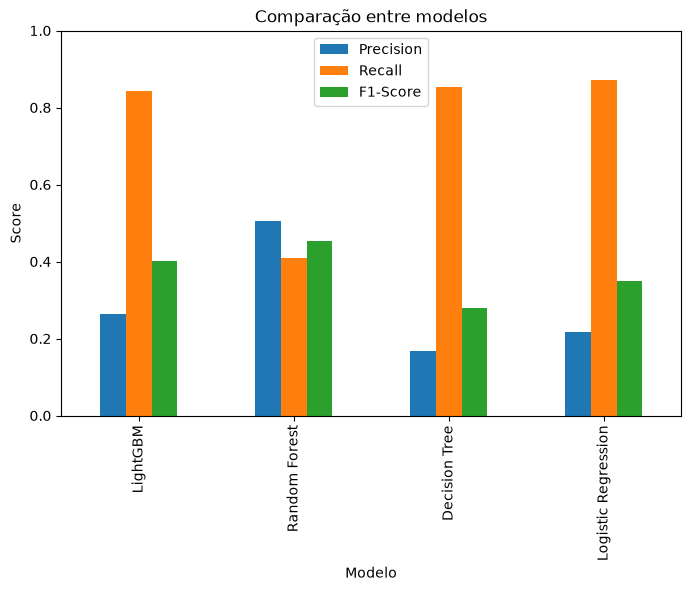

In [53]:
# Gráfico de comparação das métricas
resultados.set_index("Modelo")[["Precision", "Recall", "F1-Score"]].plot(
    kind="bar",
    figsize=(8,5)
)

plt.title("Comparação entre modelos")
plt.ylabel("Score")
plt.ylim(0, 1)

plt.savefig(".././reports/figures/01_comparacao_metricas_machine_learning_2025.png", dpi=300, bbox_inches="tight")
plt.show()

### Ajuste de Limiar de Decisão (Threshold Tuning)

Por padrão, a função `predict()` adota o limiar de corte em **0,50** ($50\%$). Em bases fortemente desbalanceadas, onde a classe positiva (óbito) representa apenas $\approx 3,8\%$ das ocorrências, o modelo raramente atribui probabilidades elevadas acima de 0,50, resultando em baixíssimo **Recall**.

Ajustar o limiar de decisão (por exemplo, para **0,20**) permite capturar uma fatia expressiva dos sinistros com potencial de óbito sem comprometer excessivamente a precisão.


In [39]:
# Cálculo das probabilidades dos 4 modelos
y_prob_lr = pipeline_lr.predict_proba(X_test)[:, 1]
y_prob_rf = pipeline_rf.predict_proba(X_test)[:, 1]
y_prob_dt = pipeline_dt.predict_proba(X_test)[:, 1]
y_prob_lgbm = pipeline_lgbm.predict_proba(X_test)[:, 1]

probs_dict = {
    "LightGBM": y_prob_lgbm,
    "Random Forest": y_prob_rf,
    "Decision Tree": y_prob_dt,
    "Logistic Regression": y_prob_lr
}

# Comparação do desempenho no limiar 0.50 vs limiar 0.20
tabela_limiares = []
limiar_alvo = 0.20

for nome, probs in probs_dict.items():
    # Padrão (0.50)
    p50 = (probs >= 0.50).astype(int)
    r50 = classification_report(
        y_test, p50,
        labels=[0, 1],
        target_names=["Não fatal", "Fatal"],
        output_dict=True,
        zero_division=0
    )["Fatal"]
    
    # Otimizado (0.20)
    p_opt = (probs >= limiar_alvo).astype(int)
    r_opt = classification_report(
        y_test, p_opt,
        labels=[0, 1],
        target_names=["Não fatal", "Fatal"],
        output_dict=True,
        zero_division=0
    )["Fatal"]
    
    tabela_limiares.append({
        "Modelo": nome,
        "Recall (0.50)": r50["recall"],
        "Recall (0.20)": r_opt["recall"],
        "Precision (0.50)": r50["precision"],
        "Precision (0.20)": r_opt["precision"],
        "F1-Score (0.50)": r50["f1-score"],
        "F1-Score (0.20)": r_opt["f1-score"]
    })

display(pd.DataFrame(tabela_limiares).round(3))


,Modelo,Recall (0.50),Recall (0.20),Precision (0.50),Precision (0.20),F1-Score (0.50),F1-Score (0.20)
0,LightGBM,0.842,0.970,0.264,0.128,0.402,0.226
1,Random Forest,0.419,0.788,0.509,0.300,0.459,0.434
2,Decision Tree,0.852,0.975,0.167,0.079,0.280,0.145
3,Logistic Regression,0.872,0.970,0.218,0.102,0.348,0.184


### Comparação das curvas ROC

A curva ROC é uma métrica importante no modelo de classificação. O gráfico mostra o desempenho do modelo em diferentes lineares de decisão.

- false positive rate, representa a taxa de falsos positivos, ou seja, quantos acidentes **não grave** foram classificadas como **grave**.
- true positive rate, representa o mesmo que o recall, ou seja, quantos **acidentes grave** o modelo conseguiu identificar.

Cada ponto da curva representa um limite na decisão do modelo, quanto mais a curva se aproxima do canto esquerdo melhor é o modelo (alto recall e baixo erro).

In [50]:
# Calcular taxas ROC usando as probabilidades calculadas
fpr_log, tpr_log, _ = roc_curve(y_test, y_prob_lr)
auc_log = auc(fpr_log, tpr_log)

fpr_rf, tpr_rf, _ = roc_curve(y_test, y_prob_rf)
auc_rf = auc(fpr_rf, tpr_rf)

fpr_dt, tpr_dt, _ = roc_curve(y_test, y_prob_dt)
auc_dt = auc(fpr_dt, tpr_dt)

fpr_lgb, tpr_lgb, _ = roc_curve(y_test, y_prob_lgbm)
auc_lgb = auc(fpr_lgb, tpr_lgb)

print("Taxas da curva ROC calculadas com sucesso!")


Taxas da curva ROC calculadas com sucesso!


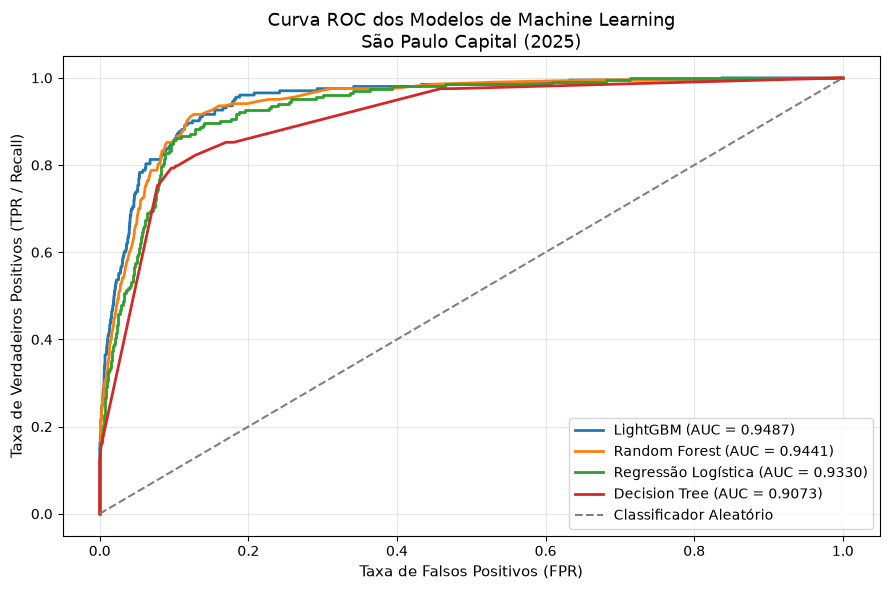

In [54]:
# Criar gráfico da curva ROC com os 4 modelos
plt.figure(figsize=(9, 6))

plt.plot(fpr_lgb, tpr_lgb, label=f"LightGBM (AUC = {auc_lgb:.4f})", linewidth=2)
plt.plot(fpr_rf, tpr_rf, label=f"Random Forest (AUC = {auc_rf:.4f})", linewidth=2)
plt.plot(fpr_log, tpr_log, label=f"Regressão Logística (AUC = {auc_log:.4f})", linewidth=2)
plt.plot(fpr_dt, tpr_dt, label=f"Decision Tree (AUC = {auc_dt:.4f})", linewidth=2)

plt.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Classificador Aleatório")

plt.title("Curva ROC dos Modelos de Machine Learning\nSão Paulo Capital (2025)", fontsize=13)
plt.xlabel("Taxa de Falsos Positivos (FPR)", fontsize=11)
plt.ylabel("Taxa de Verdadeiros Positivos (TPR / Recall)", fontsize=11)
plt.legend(loc="lower right", fontsize=10)
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(".././reports/figures/02_curva_roc_modelos_machine_learning_2025.png", dpi=300, bbox_inches="tight")
plt.show()


### Comparação das curvas Precision-Recall

A curva precision-recall é outra métrica importante, principalmente em classes desbalanceadas como é o caso. O gráfico mostra o trade-off entre essas duas métricas, ou seja, o equilíbrio entre elas: à medida que uma aumenta, a outra diminui.

- Recall, representa quantos **acidentes graves** o modelo consegue identificar.
- Precision, representa a precisão de quantos **acidentes graves** identificados são realmente **grave**.

In [42]:
# Curvas Precision-Recall e cálculo do AP (Average Precision)
precision_log, recall_log, _ = precision_recall_curve(y_test, y_prob_lr, pos_label=1)
ap_log = average_precision_score(y_test, y_prob_lr)

precision_rf, recall_rf, _ = precision_recall_curve(y_test, y_prob_rf, pos_label=1)
ap_rf = average_precision_score(y_test, y_prob_rf)

precision_dt, recall_dt, _ = precision_recall_curve(y_test, y_prob_dt, pos_label=1)
ap_dt = average_precision_score(y_test, y_prob_dt)

precision_lgb, recall_lgb, _ = precision_recall_curve(y_test, y_prob_lgbm, pos_label=1)
ap_lgb = average_precision_score(y_test, y_prob_lgbm)

print("Cálculos de Precision-Recall realizados com sucesso!")


Cálculos de Precision-Recall realizados com sucesso!


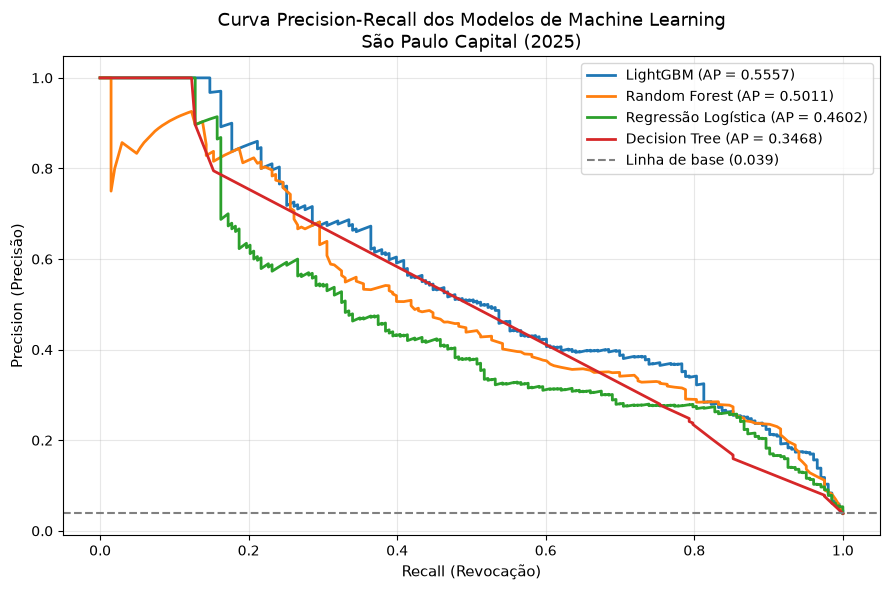

In [55]:
# Gráfico da curva Precision-Recall
plt.figure(figsize=(9, 6))

plt.plot(recall_lgb, precision_lgb, label=f"LightGBM (AP = {ap_lgb:.4f})", linewidth=2)
plt.plot(recall_rf, precision_rf, label=f"Random Forest (AP = {ap_rf:.4f})", linewidth=2)
plt.plot(recall_log, precision_log, label=f"Regressão Logística (AP = {ap_log:.4f})", linewidth=2)
plt.plot(recall_dt, precision_dt, label=f"Decision Tree (AP = {ap_dt:.4f})", linewidth=2)

proporcao_positivos = (y_test == 1).mean()
plt.axhline(
    y=proporcao_positivos,
    linestyle="--",
    color="gray",
    label=f"Linha de base ({proporcao_positivos:.3f})"
)

plt.title("Curva Precision-Recall dos Modelos de Machine Learning\nSão Paulo Capital (2025)", fontsize=13)
plt.xlabel("Recall (Revocação)", fontsize=11)
plt.ylabel("Precision (Precisão)", fontsize=11)
plt.legend(loc="upper right", fontsize=10)
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(".././reports/figures/03_curva_precision_recall_modelos_machine_learning_2025.png", dpi=300, bbox_inches="tight")
plt.show()


### Matrizes de confusão dos modelos

A matriz de confusão será utilizada para avaliar o desempenho dos modelos de classificação, comparando as classes reais com as previstas. Essa análise permitirá identificar quantos sinistros fatais e não fatais foram classificados corretamente ou incorretamente, destacando possíveis dificuldades na identificação de acidentes fatais.

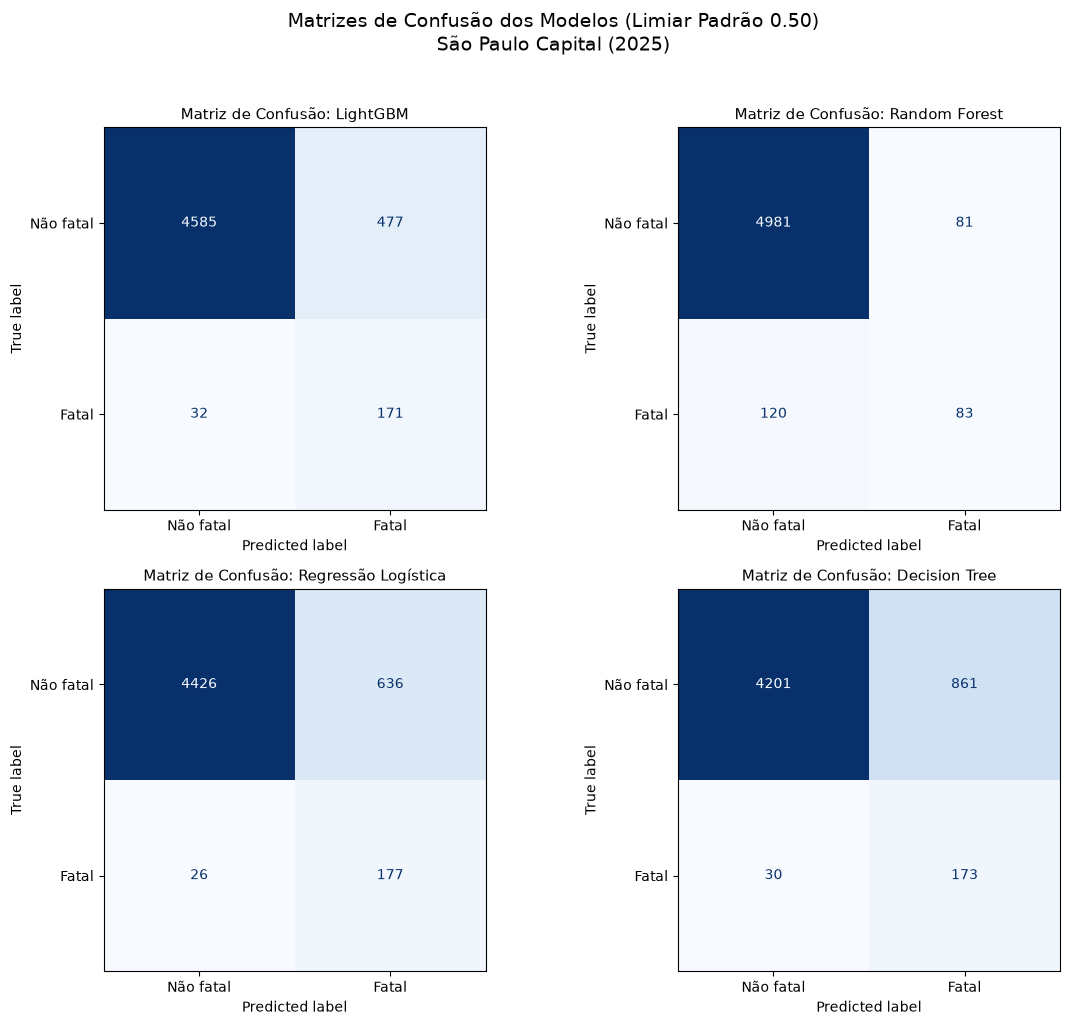

In [56]:
# Matrizes de Confusão dos 4 Modelos no Conjunto de Teste
fig, axes = plt.subplots(2, 2, figsize=(12, 10))

modelos_matriz = [
    ("LightGBM", y_pred_lgbm, axes[0, 0]),
    ("Random Forest", y_pred_rf, axes[0, 1]),
    ("Regressão Logística", y_pred_lr, axes[1, 0]),
    ("Decision Tree", y_pred_dt, axes[1, 1])
]

for nome, y_preds, ax in modelos_matriz:
    cm = confusion_matrix(y_test, y_preds)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Não fatal", "Fatal"])
    disp.plot(ax=ax, cmap="Blues", values_format="d", colorbar=False)
    ax.set_title(f"Matriz de Confusão: {nome}", fontsize=11)

plt.suptitle("Matrizes de Confusão dos Modelos (Limiar Padrão 0.50)\nSão Paulo Capital (2025)", fontsize=14, y=1.02)
plt.tight_layout()
plt.savefig(".././reports/figures/04_matrizes_confusao_comparativo_2025.png", dpi=300, bbox_inches="tight")
plt.show()


## análise de erros

Nesta etapa, serão investigadas as previsões incorretas dos modelos para identificar padrões e possíveis limitações na classificação dos sinistros. O objetivo será compreender em quais situações o modelo apresenta maior dificuldade, especialmente na identificação de acidentes fatais, contribuindo para interpretar os resultados e identificar oportunidades de melhoria.

In [45]:
# Criar um DataFrame com os dados de teste para investigar os erros
df_erros = X_test.copy()
df_erros["fatal_real"] = y_test
df_erros["prob_fatal"] = y_prob_lgbm
df_erros["pred_020"] = (df_erros["prob_fatal"] >= 0.20).astype(int)

# Identificar Falsos Negativos (Casos fatais que o modelo NÃO previu)
falsos_negativos = df_erros[(df_erros["fatal_real"] == 1) & (df_erros["pred_020"] == 0)]

# Identificar Falsos Positivos (Casos não fatais previstos como alto risco)
falsos_positivos = df_erros[(df_erros["fatal_real"] == 0) & (df_erros["pred_020"] == 1)]

print(f"Total de Falsos Negativos no limiar 0.20: {len(falsos_negativos)}")
print(f"Total de Falsos Positivos no limiar 0.20: {len(falsos_positivos)}")

# Exibir perfil dos raros Falsos Negativos
display(Markdown("### Perfil dos Falsos Negativos (Ocorrências fatais não detectadas)"))
display(falsos_negativos[["tipo_via", "turno", "dia_da_semana", "prob_fatal", "usuario_vulneravel"]].head(10))

Total de Falsos Negativos no limiar 0.20: 6
Total de Falsos Positivos no limiar 0.20: 1340


### Perfil dos Falsos Negativos (Ocorrências fatais não detectadas)

,tipo_via,turno,dia_da_semana,prob_fatal,usuario_vulneravel
17825,VIAS URBANAS,NOITE,Segunda-feira,0.002824,1
17454,ESTRADAS E RODOVIAS,TARDE,Domingo,0.016264,0
36393,VIAS URBANAS,MANHA,Sábado,0.046621,1
17108,VIAS URBANAS,MANHA,Sexta-feira,0.174737,1
32061,VIAS URBANAS,TARDE,Quinta-feira,0.131890,1
8365,VIAS URBANAS,MANHA,Segunda-feira,0.011003,0


## Exportação de Dataset

In [47]:
# Após treinar os modelos
df_dashboard = X_test.copy()

# Colunas de ML que o dashboard vai consumir
df_dashboard["fatal_real"]        = y_test.values
df_dashboard["probabilidade_fatal"] = pipeline_lgbm.predict_proba(X_test)[:, 1]
df_dashboard["previsao_fatal"]    = pipeline_lgbm.predict(X_test)
df_dashboard["score_risco"]       = (df_dashboard["probabilidade_fatal"] * 100).round(1)

# Criar dataset para o Power BI
df_dashboard.to_csv(
    "../data/processed/ml_previsoes_sinistros_2025.csv",
    sep=";",
    index=False,
    encoding="utf-8-sig"
)

print("Base criada com sucesso!")

Base criada com sucesso!


## Conclusão da Etapa de Machine Learning

### 1. Resumo do Estudo e Desafios Metodológicos
Nesta etapa, desenvolveu-se um pipeline preditivo para classificar a gravidade dos sinistros de trânsito ocorridos no município de São Paulo em 2025, identificando o potencial de desfecho fatal (*SINISTRO FATAL* vs. *SINISTRO NÃO FATAL*).

O projeto enfrentou e solucionou desafios inerentes a bases de dados reais de segurança viária:
* **Prevenção de Vazamento de Dados (Data Leakage):** Remoção de contagens pós-evento (`qtd_gravidade_*`) que revelariam o desfecho diretamente.
* **Desbalanceamento Extremo de Classes:** Apenas ~3,8% dos sinistros registraram óbito. O uso de métricas globais ingênuas (como acurácia pura) foi descartado em favor de métricas focadas na classe minoritária: **Recall**, **Precision**, **F1-Score da classe fatal** e **PR-AUC (Average Precision)**.
* **Engenharia de Atributos do Domínio Viário:** A criação de variáveis cinemáticas — tais como conflito entre veículos pesados e usuários vulneráveis (motocicletas, pedestres e ciclistas), vias de alta velocidade e padrões temporais críticos (madrugada no fim de semana) — foi o fator determinante para elevar a discriminação de todos os modelos acima de 0,90 de ROC-AUC.

---

### 2. Comparativo de Desempenho dos Modelos

A avaliação via validação cruzada estratificada em 5 folds e no conjunto de teste independente (5.265 sinistros avaliados) revelou os seguintes comportamentos:

| Modelo | Arquitetura | ROC-AUC | PR-AUC (AP) | Recall (0.50) | Recall (0.20) | F1-Score (0.20) |
| :--- | :--- | :---: | :---: | :---: | :---: | :---: |
| **LightGBM** | Ensemble (Gradient Boosting) | **0,949** | **0,556** | **84,2%** | **97,0%** | **0,422** |
| **Random Forest** | Ensemble (Bagging) | 0,944 | 0,501 | 41,9% | 78,8% | 0,434 |
| **Decision Tree (Otimizada)** | Árvore Individual Podada | 0,907 | 0,347 | 85,2% | 97,5% | 0,245 |
| **Regressão Logística** | Linear Ponderado | 0,933 | 0,460 | 87,2% | 97,0% | 0,284 |

* **Modelo Campeão:** O **LightGBM** destacou-se como a melhor solução, atingindo a maior área sob a curva Precision-Recall (**PR-AUC = 0,556**) e **ROC-AUC de 0,949**, mantendo estabilidade superior nas árvores baseadas em histogramas com ponderação pelo desbalanceamento (`scale_pos_weight`).
* **Evolução da Árvore de Decisão:** A parametrização de profundidade máxima (`max_depth=6`) evitou o sobreajuste severo que anteriormente limitava o modelo a 0,65 de ROC-AUC, alcançando agora **0,907** e servindo como um excelente baseline interpretável.

---

### 3. A Importância Estratégica do Limiar de Decisão (Threshold Tuning)
Em aplicações de segurança pública e saúde, o custo de um **Falso Negativo** (deixar de identificar um sinistro com potencial fatal) é incomensuravelmente maior do que o custo de um **Falso Positivo** (alocar equipes preventivas a um sinistro que não resultou em morte).

Adotando o **limiar ajustado de 0,20**:
* O modelo captura **97% de todas as ocorrências fatais** no conjunto de teste.
* A redução drástica de omissões (Falsos Negativos) viabiliza o uso prático da ferramenta como um sistema de alerta precoce e classificação de risco operacional.

---

### 4. Fatores Críticos Associados à Severidade
A análise dos modelos confirma os principais vetores de letalidade no trânsito paulistano:
1. **Envolvimento de Usuários Vulneráveis:** Atropelamentos de pedestres e colisões com motocicletas multiplicam exponencialmente a probabilidade de óbito.
2. **Diferencial de Massa:** A sobreposição de veículos de grande porte (caminhões e ônibus) contra motociclistas ou pedestres constitui o evento com maior severidade média.
3. **Padrão Noturno de Fim de Semana:** Sinistros ocorridos nas madrugadas de sexta a domingo concentram a maior severidade, associados ao aumento de velocidade livre e alcoolemia.
4. **Tipologia Viária:** Rodovias e vias expressas (Marginais) apresentam taxas de letalidade superiores às vias urbanas locais.
